# Sélection du LLM — Analyse des résultats

**SmartCampus AI — Epic « Sélection et intégration du LLM »**

Ce notebook analyse les réponses des modèles enregistrées par `run_benchmark.py` (dossier `results/`). Il ne relance pas les modèles.

| Tâche | Ce qui est mesuré |
|---|---|
| **SA-33** — Comparer les performances des modèles LLM | Justesse en français, capacité exploratoire en tunisien et Arabizi, latence, coûts, erreurs |
| **SA-34** — Dialecte tunisien et Arabizi | Compréhension du modèle sélectionné en tunisien, Arabizi et mixte ; erreurs rencontrées |

**Modèles comparés :** Gemma 4 E2B (Google), Qwen 3.5 4B (Alibaba), Llama 3.2 3B (Meta) — open-source, exécutés en local via Ollama.

**Jeu de test :** 60 questions — 30 en français (admission, orientation, reformulations, cas ambigus) et 30 en tunisien écrit en arabe, Arabizi et mixte.

## 1. Imports et paramètres

In [2]:
import glob, json, os, re, unicodedata
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix

RESULTS = "results"
FIGURES = os.path.join(RESULTS, "figures")
os.makedirs(FIGURES, exist_ok=True)

MODELES = ["gemma4:e2b-it-qat", "qwen3.5:4b", "llama3.2:3b"]
NOMS = {"gemma4:e2b-it-qat": "Gemma 4 E2B", "qwen3.5:4b": "Qwen 3.5 4B", "llama3.2:3b": "Llama 3.2 3B"}
COULEURS = ["#2a78d6", "#eb6834", "#1baf7a"]
LANGUES = {"fr": "Français", "tn_ar": "Tunisien (arabe)", "arabizi": "Arabizi", "mixte": "Mixte"}
INTENTIONS = ["SALUTATION", "INFO_FORMATION", "COMPARAISON", "ORIENTATION", "PROFIL", "PREINSCRIPTION", "HORS_SUJET"]
MODELE_RETENU = "gemma4:e2b-it-qat"

# Espace disque des modèles téléchargés (affiché par `ollama list`)
TAILLE_DISQUE_GO = {"gemma4:e2b-it-qat": 4.3, "qwen3.5:4b": 3.4, "llama3.2:3b": 2.0}

## 2. Chargement des réponses des modèles et de l'annotation humaine

- `raw_*.jsonl` : une ligne par question et par modèle (réponse JSON du modèle, latence, tokens).
- `a_annoter.csv` : évaluation humaine de chaque réponse — pertinence (1 à 5), registre adapté (0/1), hallucination (0/1).

In [3]:
lignes = []
for fichier in glob.glob(os.path.join(RESULTS, "raw_*.jsonl")):
    with open(fichier, encoding="utf-8") as f:
        lignes += [json.loads(l) for l in f if l.strip()]
df = pd.DataFrame(lignes)

annot = pd.read_csv(os.path.join(RESULTS, "a_annoter.csv"), encoding="utf-8-sig")
annot = annot[["model", "id", "pertinence_1_5", "registre_ok_0_1", "hallucination_0_1", "commentaire"]]
df = df.merge(annot, on=["model", "id"], how="left")

df["groupe"] = df["langue_attendue"].map(lambda l: "Français" if l == "fr" else "Dialecte")
df["categorie"] = df["categorie"].fillna("base")
print(f"{len(df)} réponses chargées — {df['model'].nunique()} modèles, {df['id'].nunique()} questions")
print("Réponses sans annotation humaine :", int(df["pertinence_1_5"].isna().sum()))
df.groupby(["model", "groupe"]).size().unstack()

180 réponses chargées — 3 modèles, 60 questions
Réponses sans annotation humaine : 0


groupe,Dialecte,Français
model,,
gemma4:e2b-it-qat,30,30
llama3.2:3b,30,30
qwen3.5:4b,30,30


## 3. Correction automatique de chaque réponse

Pour chaque réponse, on compare la sortie du modèle à ce qui était attendu :

- **intention** prédite vs intention attendue ;
- **langue** détectée vs langue réelle du message ;
- **profil** : informations du candidat (section, moyenne, intérêts, contraintes) retrouvées par le modèle ;
- **écriture** : la réponse utilise-t-elle l'alphabet du candidat (arabe ou latin) ?

Pour le profil, le modèle peut écrire la même information autrement (« maths », « mathématiques », « رياضيات »). Le dictionnaire `SYNONYMES` liste les formes acceptées pour chaque valeur attendue.

In [4]:
SYNONYMES = {
    "mathematiques": ["math", "رياضيات", "riadhiyet", "riadhiyat", "riyadiyat"],
    "informatique": ["info", "إعلامية", "اعلامية", "computer", "حاسوب"],
    "sciences experimentales": ["experiment", "sciences exp", "تجريبية"],
    "technique": ["techni", "تقنية"],
    "physique": ["physi", "فيزياء", "فيزيك"],
    "pratique": ["pratiq", "practic", "تطبيق", "applique"],
    "progressive": ["progress", "تدريجي"],
    "developpement": ["developp", "programm", "برمجة", "coding"],
    "programmation": ["programm", "developp", "برمجة", "coding"],
    "terminale": ["terminal", "lycee"],
    "genie logiciel": ["logiciel", "software"],
    "duree courte": ["court", "short", "5 ans", "duree"],
    "geographique": ["sfax", "geograph", "wilaya", "ولاية", "region", "ville", "deplac"],
    "sfax": ["sfax", "صفاقس"],
    "web": ["web", "multimedia"],
    "marketing": ["marketing", "ماركتينغ", "تسويق"],
    "robotique": ["robot", "mecatron"],
}

def normaliser(texte):
    texte = unicodedata.normalize("NFKD", str(texte).lower())
    return "".join(c for c in texte if not unicodedata.combining(c))

def valeur_trouvee(valeur, profil_texte):
    if isinstance(valeur, bool):
        return valeur and any(m in profil_texte for m in ["true", "oui", "contact", "rappel", "appel"])
    if isinstance(valeur, (int, float)):
        return re.search(rf"(?<!\d){int(valeur)}(?!\d)", profil_texte) is not None
    v = normaliser(valeur)
    return v in profil_texte or any(normaliser(s) in profil_texte for s in SYNONYMES.get(v, []))

def corriger(ligne):
    sortie = ligne["sortie"] if isinstance(ligne["sortie"], dict) else {}
    reponse = str(sortie.get("reponse", ""))
    attendu = [x for v in ligne["profil_attendu"].values() for x in (v if isinstance(v, list) else [v])]
    profil_texte = normaliser(json.dumps(sortie.get("profil", {}), ensure_ascii=False))
    lettres = [c for c in reponse if c.isalpha()]
    part_arabe = sum("\u0600" <= c <= "\u06FF" for c in lettres) / len(lettres) if lettres else 0
    ecriture_ok = {"fr": part_arabe < 0.1, "tn_ar": part_arabe > 0.5, "arabizi": part_arabe < 0.3}.get(ligne["langue_attendue"], True)
    return pd.Series({
        "json_valide": isinstance(ligne["sortie"], dict),
        "reponse": reponse,
        "reponse_vide": reponse.strip() == "",
        "intention_predite": str(sortie.get("intention", "")).upper() or "(vide)",
        "langue_predite": str(sortie.get("langue", "")).lower(),
        "profil_attendu_n": len(attendu),
        "profil_trouve_n": sum(valeur_trouvee(v, profil_texte) for v in attendu),
        "ecriture_ok": bool(reponse) and ecriture_ok,
    })

df = pd.concat([df, df.apply(corriger, axis=1)], axis=1)
df["intention_ok"] = df["intention_predite"] == df["intention_attendue"]
df["langue_ok"] = df["langue_predite"] == df["langue_attendue"]
df[["model", "id", "intention_attendue", "intention_predite", "langue_attendue", "langue_predite", "profil_trouve_n", "profil_attendu_n"]].head(10)

,model,id,intention_attendue,intention_predite,langue_attendue,langue_predite,profil_trouve_n,profil_attendu_n
0,gemma4:e2b-it-qat,FR-01,SALUTATION,INFO_FORMATION,fr,fr,0,1
1,gemma4:e2b-it-qat,FR-02,INFO_FORMATION,INFO_FORMATION,fr,fr,0,0
2,gemma4:e2b-it-qat,FR-03,COMPARAISON,COMPARAISON,fr,fr,0,0
3,gemma4:e2b-it-qat,FR-04,ORIENTATION,ORIENTATION,fr,fr,2,3
4,gemma4:e2b-it-qat,FR-05,INFO_FORMATION,INFO_FORMATION,fr,fr,0,0
5,gemma4:e2b-it-qat,FR-06,PREINSCRIPTION,PREINSCRIPTION,fr,fr,0,0
6,gemma4:e2b-it-qat,FR-07,INFO_FORMATION,COMPARAISON,fr,fr,0,0
7,gemma4:e2b-it-qat,FR-08,PROFIL,ORIENTATION,fr,fr,1,2
8,gemma4:e2b-it-qat,FR-09,HORS_SUJET,HORS_SUJET,fr,fr,0,0
9,gemma4:e2b-it-qat,FR-10,INFO_FORMATION,ORIENTATION,fr,fr,1,1


## 4. Métriques

| Métrique | Ce qu'elle mesure |
|---|---|
| **Accuracy** | Proportion d'intentions correctement identifiées |
| **Macro-F1** | Moyenne des F1 par intention, sans favoriser les intentions fréquentes |
| **Recall** | Proportion des informations du profil correctement extraites |
| **Answer Relevancy** | Pertinence de la réponse, notée de 1 à 5 (évaluation humaine) |
| **Hallucination Rate** | Proportion de réponses contenant une information inventée (évaluation humaine) |
| **Latency** | Temps moyen de réponse |
| **Throughput** | Tokens générés par seconde |


In [5]:
def metriques(d):
    recall = d["profil_trouve_n"].sum() / d["profil_attendu_n"].sum() if d["profil_attendu_n"].sum() else float("nan")
    return pd.Series({
        "Accuracy": accuracy_score(d["intention_attendue"], d["intention_predite"]),
        "Macro-F1": f1_score(d["intention_attendue"], d["intention_predite"], labels=sorted(d["intention_attendue"].unique()), average="macro", zero_division=0),
        "Recall": recall,
        "Answer Relevancy": d["pertinence_1_5"].mean(),
        "Hallucination Rate": d["hallucination_0_1"].mean(),
        "Latency (s)": d["latence_s"].mean(),
        "Throughput (tokens/s)": d["tokens_par_s"].mean(),
        "Détection de la langue": d["langue_ok"].mean(),
        "Registre adapté": d["registre_ok_0_1"].mean(),
        "Écriture adaptée": d["ecriture_ok"].mean(),
    })

def tableau(d):
    t = d.groupby("model").apply(metriques).loc[MODELES]
    t.index = [NOMS[m] for m in t.index]
    return t

FORMATS = {"Accuracy": "{:.0%}", "Macro-F1": "{:.2f}", "Recall": "{:.0%}", "Answer Relevancy": "{:.2f}",
           "Hallucination Rate": "{:.1%}", "Latency (s)": "{:.1f}", "Throughput (tokens/s)": "{:.1f}",
           "Détection de la langue": "{:.0%}", "Registre adapté": "{:.0%}", "Écriture adaptée": "{:.0%}"}
METRIQUES_PRINCIPALES = ["Accuracy", "Macro-F1", "Recall", "Answer Relevancy", "Hallucination Rate"]

## 5. SA-33 — Justesse en français (30 questions)

Critère principal : le modèle doit **comprendre les questions en français et générer des réponses pertinentes**.

In [6]:
fr = tableau(df[df["groupe"] == "Français"])
fr[METRIQUES_PRINCIPALES].style.format(FORMATS)

C:\Users\ASUS\AppData\Local\Temp\ipykernel_12972\2477065154.py:17: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  t = d.groupby("model").apply(metriques).loc[MODELES]


,Accuracy,Macro-F1,Recall,Answer Relevancy,Hallucination Rate
Gemma 4 E2B,67%,0.54,75%,3.67,3.3%
Qwen 3.5 4B,83%,0.63,100%,3.10,53.3%
Llama 3.2 3B,47%,0.29,94%,2.23,50.0%


### Par catégorie de question (français)

In [7]:
cat = (df[df["groupe"] == "Français"]
       .groupby(["categorie", "model"])
       .apply(lambda d: pd.Series({"Accuracy": d["intention_ok"].mean(), "Answer Relevancy": d["pertinence_1_5"].mean(), "n": len(d)}))
       .unstack("model"))
cat = cat.rename(index={"base": "questions générales", "cas_ambigu": "cas ambigus"})
cat.style.format("{:.2f}")

C:\Users\ASUS\AppData\Local\Temp\ipykernel_12972\867366343.py:3: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda d: pd.Series({"Accuracy": d["intention_ok"].mean(), "Answer Relevancy": d["pertinence_1_5"].mean(), "n": len(d)}))


**Reformulations :** une question reformulée doit être comprise comme la question d'origine (même intention prédite).

In [8]:
ref = df[df["categorie"] == "reformulation"][["model", "id", "question_d_origine", "intention_predite"]]
origine = df[["model", "id", "intention_predite"]].rename(columns={"id": "question_d_origine", "intention_predite": "intention_origine"})
ref = ref.merge(origine, on=["model", "question_d_origine"])
ref["coherent"] = ref["intention_predite"] == ref["intention_origine"]
coherence = ref.groupby("model")["coherent"].agg(["sum", "count"]).loc[MODELES]
coherence.index = [NOMS[m] for m in coherence.index]
coherence.rename(columns={"sum": "reformulations comprises comme l'original", "count": "total"})

,reformulations comprises comme l'original,total
Gemma 4 E2B,5,6
Qwen 3.5 4B,6,6
Llama 3.2 3B,3,6


## 6. SA-33 — Capacité exploratoire en tunisien et Arabizi (30 questions)

In [9]:
dial = tableau(df[df["groupe"] == "Dialecte"])
dial[METRIQUES_PRINCIPALES + ["Détection de la langue", "Registre adapté"]].style.format(FORMATS)

C:\Users\ASUS\AppData\Local\Temp\ipykernel_12972\2477065154.py:17: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  t = d.groupby("model").apply(metriques).loc[MODELES]


,Accuracy,Macro-F1,Recall,Answer Relevancy,Hallucination Rate,Détection de la langue,Registre adapté
Gemma 4 E2B,73%,0.77,62%,3.13,3.3%,27%,43%
Qwen 3.5 4B,70%,0.72,90%,2.17,40.0%,60%,73%
Llama 3.2 3B,40%,0.41,48%,1.77,26.7%,13%,33%


## 7. SA-33 — Latence et coûts (60 requêtes)

In [10]:
glob_ = tableau(df)
couts = pd.DataFrame({
    "Latency (s)": glob_["Latency (s)"],
    "Throughput (tokens/s)": glob_["Throughput (tokens/s)"],
    "Tokens générés par réponse": df.groupby("model")["tokens_generes"].mean().loc[MODELES].values,
    "Temps pour 60 requêtes (min)": df.groupby("model")["latence_s"].sum().loc[MODELES].values / 60,
    "Requêtes par heure": 3600 / glob_["Latency (s)"],
    "Espace disque (Go)": [TAILLE_DISQUE_GO[m] for m in MODELES],
    "Coût licence / API": ["0 (Apache 2.0)", "0 (Apache 2.0)", "0 (Llama Community)"],
}, index=glob_.index)
couts.style.format({"Latency (s)": "{:.1f}", "Throughput (tokens/s)": "{:.1f}", "Tokens générés par réponse": "{:.0f}",
                    "Temps pour 60 requêtes (min)": "{:.0f}", "Requêtes par heure": "{:.0f}", "Espace disque (Go)": "{:.1f}"})

C:\Users\ASUS\AppData\Local\Temp\ipykernel_12972\2477065154.py:17: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  t = d.groupby("model").apply(metriques).loc[MODELES]


,Latency (s),Throughput (tokens/s),Tokens générés par réponse,Temps pour 60 requêtes (min),Requêtes par heure,Espace disque (Go),Coût licence / API
Gemma 4 E2B,19.0,6.5,119,19,190,4.3,0 (Apache 2.0)
Qwen 3.5 4B,54.8,4.5,142,55,66,3.4,0 (Apache 2.0)
Llama 3.2 3B,47.2,4.3,186,47,76,2.0,0 (Llama Community)


## 8. SA-33 — Erreurs (sur 60 requêtes)

In [11]:
erreurs = df.groupby("model").apply(lambda d: pd.Series({
    "Sortie JSON invalide": int((~d["json_valide"]).sum()),
    "Réponse vide": int(d["reponse_vide"].sum()),
    "Mauvaise intention": int((~d["intention_ok"]).sum()),
    "Mauvaise langue détectée": int((~d["langue_ok"]).sum()),
    "Information inventée": int(d["hallucination_0_1"].sum()),
})).loc[MODELES]
erreurs.index = [NOMS[m] for m in erreurs.index]
erreurs

C:\Users\ASUS\AppData\Local\Temp\ipykernel_12972\1611755894.py:1: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  erreurs = df.groupby("model").apply(lambda d: pd.Series({


,Sortie JSON invalide,Réponse vide,Mauvaise intention,Mauvaise langue détectée,Information inventée
Gemma 4 E2B,1,1,18,23,2
Qwen 3.5 4B,0,0,14,17,28
Llama 3.2 3B,3,3,34,50,23


### Matrices de confusion (intention attendue → intention prédite)

Chaque ligne est une intention attendue, chaque colonne l'intention prédite par le modèle. La diagonale correspond aux bonnes réponses.

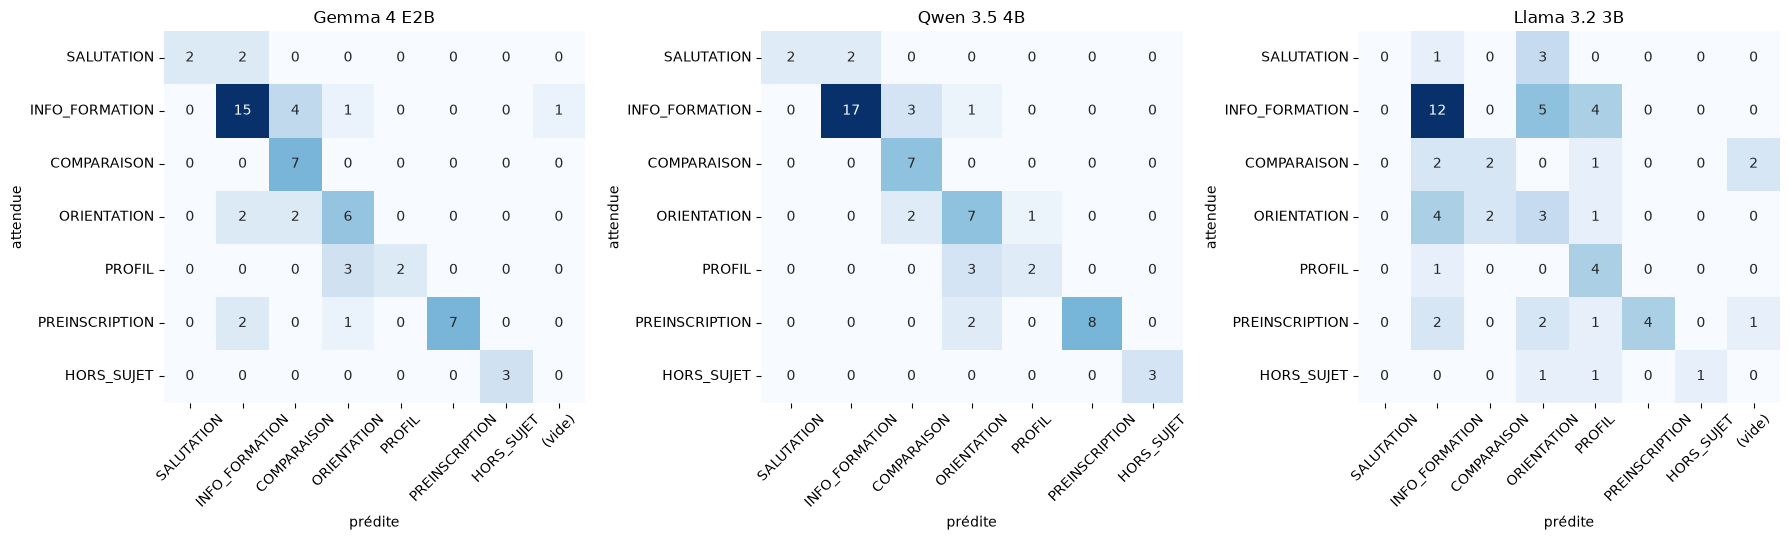

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))
for ax, m in zip(axes, MODELES):
    d = df[df["model"] == m]
    etiquettes = INTENTIONS + sorted(set(d["intention_predite"]) - set(INTENTIONS))
    mat = confusion_matrix(d["intention_attendue"], d["intention_predite"], labels=etiquettes)
    sns.heatmap(mat[:len(INTENTIONS)], annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
                xticklabels=etiquettes, yticklabels=INTENTIONS)
    ax.tick_params(axis="x", rotation=45)
    ax.set_title(NOMS[m]); ax.set_xlabel("prédite"); ax.set_ylabel("attendue")
plt.tight_layout(); plt.savefig(os.path.join(FIGURES, "matrices_confusion.png"), dpi=150); plt.show()

## 9. SA-33 — Comparaison graphique

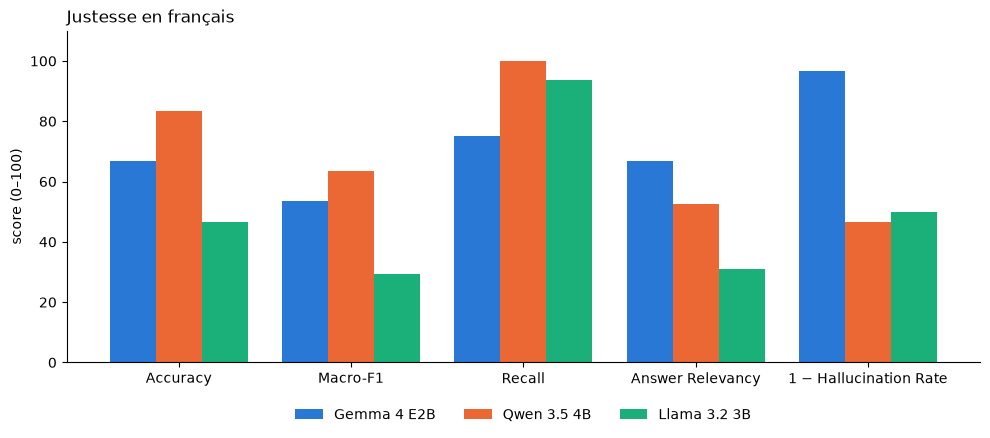

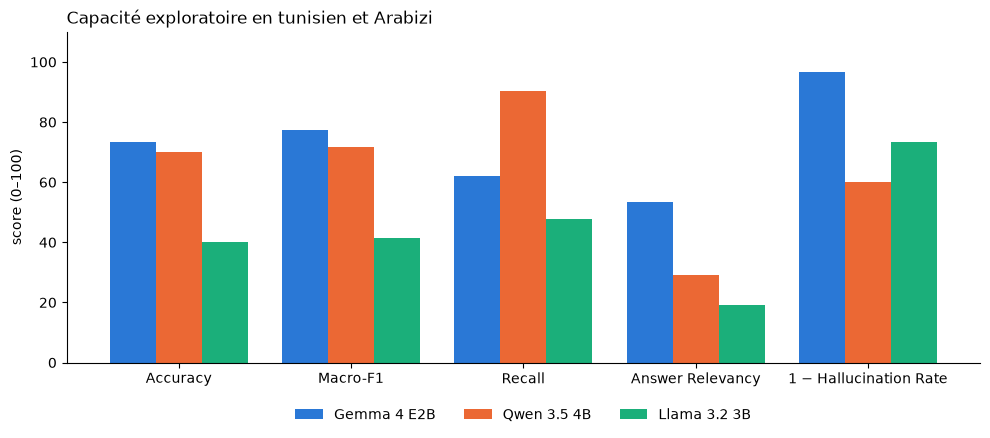

In [13]:
def graphique(t, titre, fichier):
    v = t[METRIQUES_PRINCIPALES].copy()
    v["Answer Relevancy"] = (v["Answer Relevancy"] - 1) / 4          # ramenée sur 0–1
    v["1 − Hallucination Rate"] = 1 - v.pop("Hallucination Rate")
    ax = (v.T * 100).plot.bar(figsize=(10, 4.5), color=COULEURS, width=0.8, rot=0)
    ax.set_ylim(0, 110); ax.set_ylabel("score (0–100)"); ax.set_title(titre, loc="left")
    ax.legend(frameon=False, ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.1))
    for s in ["top", "right"]: ax.spines[s].set_visible(False)
    plt.tight_layout(); plt.savefig(os.path.join(FIGURES, fichier), dpi=150); plt.show()

graphique(fr, "Justesse en français", "comparaison_francais.png")
graphique(dial, "Capacité exploratoire en tunisien et Arabizi", "comparaison_dialecte.png")

## 10. SA-33 — Score final et décision

Score sur 100, pondéré selon les priorités du projet : **le français compte pour 70 %** (critère principal), le dialecte pour 30 % (capacité exploratoire).

Pour chaque groupe : 25 % Accuracy + 15 % Recall + 10 % détection de la langue + 10 % écriture adaptée + 20 % Answer Relevancy + 20 % (1 − Hallucination Rate).

In [14]:
def score(t):
    return 100 * (0.25 * t["Accuracy"] + 0.15 * t["Recall"] + 0.10 * t["Détection de la langue"] + 0.10 * t["Écriture adaptée"]
                  + 0.20 * (t["Answer Relevancy"] - 1) / 4 + 0.20 * (1 - t["Hallucination Rate"]))

scores = pd.DataFrame({"Score français": score(fr), "Score dialecte": score(dial)})
scores["Score final"] = 0.7 * scores["Score français"] + 0.3 * scores["Score dialecte"]
scores["Latency (s)"] = glob_["Latency (s)"]
scores = scores.sort_values("Score final", ascending=False)
print("Modèle retenu :", scores.index[0])
scores.style.format("{:.1f}")

Modèle retenu : Gemma 4 E2B


,Score français,Score dialecte,Score final,Latency (s)
Gemma 4 E2B,80.2,67.0,76.3,19.0
Qwen 3.5 4B,74.0,63.2,70.8,54.8
Llama 3.2 3B,53.9,45.3,51.3,47.2


## 11. SA-34 — Le modèle sélectionné face au dialecte tunisien et à l'Arabizi

Comparaison du modèle retenu sur les quatre formes d'écriture, le français servant de référence.

In [15]:
retenu = df[df["model"] == MODELE_RETENU]
par_langue = retenu.groupby("langue_attendue").apply(metriques).loc[list(LANGUES)]
par_langue.index = [LANGUES[l] for l in par_langue.index]
par_langue[["Accuracy", "Recall", "Answer Relevancy", "Hallucination Rate", "Détection de la langue", "Registre adapté"]].T.style.format("{:.2f}")

C:\Users\ASUS\AppData\Local\Temp\ipykernel_12972\1439321974.py:2: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  par_langue = retenu.groupby("langue_attendue").apply(metriques).loc[list(LANGUES)]


,Français,Tunisien (arabe),Arabizi,Mixte
Accuracy,0.67,0.60,0.70,0.90
Recall,0.75,0.50,0.80,0.60
Answer Relevancy,3.67,2.60,3.10,3.70
Hallucination Rate,0.03,0.00,0.10,0.00
Détection de la langue,0.97,0.20,0.10,0.50
Registre adapté,1.00,0.10,0.30,0.90


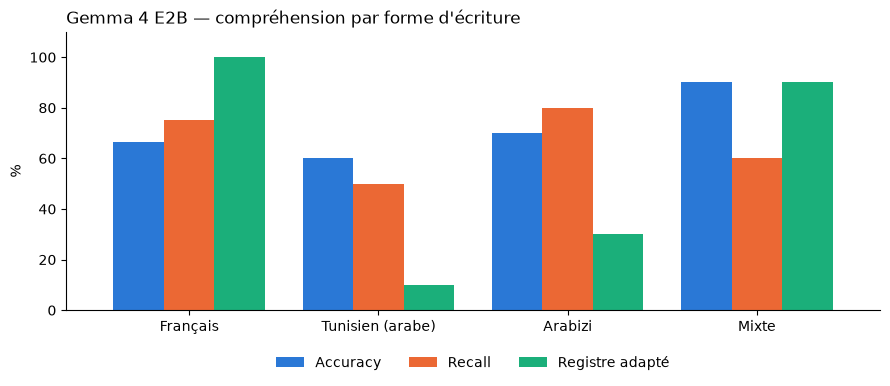

In [16]:
v = par_langue[["Accuracy", "Recall", "Registre adapté"]] * 100
ax = v.plot.bar(figsize=(9, 4), color=COULEURS, width=0.8, rot=0)
ax.set_ylim(0, 110); ax.set_ylabel("%"); ax.set_title(f"{NOMS[MODELE_RETENU]} — compréhension par forme d'écriture", loc="left")
ax.legend(frameon=False, ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.12))
for s in ["top", "right"]: ax.spines[s].set_visible(False)
plt.tight_layout(); plt.savefig(os.path.join(FIGURES, "sa34_par_langue.png"), dpi=150); plt.show()

### Erreurs et difficultés rencontrées

Réponses du modèle retenu jugées faibles (pertinence ≤ 2) en dialecte, avec le commentaire de l'annotation humaine.

In [17]:
faibles = retenu[(retenu["groupe"] == "Dialecte") & (retenu["pertinence_1_5"] <= 2)]
pd.set_option("display.max_colwidth", 120)
faibles[["id", "langue_attendue", "question", "intention_predite", "pertinence_1_5", "commentaire"]]

,id,langue_attendue,question,intention_predite,pertinence_1_5,commentaire
12,TN-03,tn_ar,جبت الباك رياضيات بـ 13 ونحب الإعلامية، شنوة تنصحني نقرا؟,ORIENTATION,2,Comprend إعلامية comme 'médias' au lieu d'informatique
13,TN-04,tn_ar,قداش تدوم القراية في الإنجينيور؟,INFO_FORMATION,2,"Texte répétitif, incohérent"
14,TN-05,tn_ar,كيفاش نعمل الإنسكريبسيون؟,PREINSCRIPTION,2,Arabizi répétitif
16,TN-07,tn_ar,بعد الليسانس نجم نكمل إنجينيور؟,(vide),1,Réponse vide
17,TN-08,tn_ar,شنوة الخدمة اللي نجم نلقاها بعد الـ ISB؟,INFO_FORMATION,2,"Vague, en français"
19,TN-10,tn_ar,نحب تعيطولي باش تفسرولي أكثر,ORIENTATION,2,"Demande de rappel non comprise, registre marocain"
23,AZ-04,arabizi,9adeh ya5ou wa9t el cycle ingénieur?,INFO_FORMATION,2,Affirme 5 ans pour le cycle ingénieur
24,AZ-05,arabizi,"Nheb nsajel fel licence, chnowa lezem?",INFO_FORMATION,2,"Boucle, mélange d'écritures"
27,AZ-08,arabizi,Chnowa el 5edma elli nal9aha ba3d ISB?,INFO_FORMATION,1,Arabizi incohérent


### Solution de repli

Lorsque le modèle ne comprend pas correctement la demande — réponse vide, sortie inexploitable, intention inconnue ou réponse incohérente — le système **demande au candidat de reformuler en français** :

> « Smahli, ma fhemtekch mli7. Tnajjem t3awed tektebha b'français ? »
> « Désolé, je n'ai pas bien compris. Peux-tu reformuler ta question en français ? »

Après deux échecs consécutifs, la conversation est orientée vers un conseiller humain.

In [18]:
repli = retenu["reponse_vide"] | ~retenu["json_valide"] | ~retenu["intention_predite"].isin(INTENTIONS)
print(f"Réponses du modèle retenu qui auraient déclenché le repli automatique : {int(repli.sum())} / {len(retenu)}")
retenu[repli][["id", "langue_attendue", "question", "intention_predite"]]

Réponses du modèle retenu qui auraient déclenché le repli automatique : 1 / 60


,id,langue_attendue,question,intention_predite
16,TN-07,tn_ar,بعد الليسانس نجم نكمل إنجينيور؟,(vide)


## 12. Export des résultats

In [19]:
fr.to_csv(os.path.join(RESULTS, "resultats_francais.csv"), encoding="utf-8-sig")
dial.to_csv(os.path.join(RESULTS, "resultats_dialecte.csv"), encoding="utf-8-sig")
couts.to_csv(os.path.join(RESULTS, "couts_latence.csv"), encoding="utf-8-sig")
erreurs.to_csv(os.path.join(RESULTS, "erreurs.csv"), encoding="utf-8-sig")
scores.to_csv(os.path.join(RESULTS, "scores.csv"), encoding="utf-8-sig")
par_langue.to_csv(os.path.join(RESULTS, "sa34_par_langue.csv"), encoding="utf-8-sig")
df.drop(columns=["sortie"]).to_csv(os.path.join(RESULTS, "details.csv"), index=False, encoding="utf-8-sig")
print("Fichiers enregistrés dans", RESULTS)

Fichiers enregistrés dans results
